In [28]:
from pathlib import Path
import ims
from skimage.io import imshow
from sympy.strategies.branch import condition

import preprocess

# Step 0: Define all necessary directories.
input_dir = Path("./data/IMS_Olive_Oil_Geography/Test/")
output_dir = Path("./output/Jupyter_Test/")

# Check and create directories if necessary.
if not output_dir.exists():
    output_dir.mkdir(parents=True, exist_ok=True)

# Step 1: Preprocess the .mea files
# - RIP Interpolation (for each dataset)
# - Background noise reduction
# - Gaussian smoothing

# Load the test dataset and interpolate to a common RIP
dataset = ims.Dataset.read_mea(input_dir)
dataset.interp_riprel()

# Get the first test spectrum.
spectrum = dataset[0]

In [7]:
# =========================================== JUST PLOTTING THE CUTTED RAW SPECTRUM ===========================================
import plot
spectrum.cut_dt(start=1.02, stop=1.2)
spectrum.cut_rt(start=100, stop=140)

# Plot the raw spectrum.
plot.single_gcims_plot(spectrum=spectrum,
                       plot_dir=output_dir,
                       condition="raw_cut")


<Figure size 1000x600 with 0 Axes>

In [29]:
# =========================================== I. PREPROCESSING ===========================================
import plot
from scipy.ndimage import uniform_filter
# Plot the raw spectrum.
plot.single_gcims_plot(spectrum=spectrum,
                       plot_dir=output_dir,
                       condition="raw",
                       peak_cords=None)

spectrum.rip_ms = 1
# Baseline correction - removing the noisy background by subtracting the mean of an empty area.
spectrum.sub_first_rows(50)
spectrum.cut_dt(start=1.02, stop=1.2)
spectrum.cut_rt(start=100, stop=140)

#uniform_filter_size= (11, 11)
#spectrum.values = uniform_filter(input=spectrum.values, size=uniform_filter_size)
#from scipy.ndimage import gaussian_filter
#spectrum.values = gaussian_filter(spectrum.values, sigma=1.0)

# Smoothing the spectrum with the Savitzky–Golay filter.
spectrum.savgol(window_length=10, polyorder=4)

# Remove negative values after applying the smooth filter.
spectrum.values[spectrum.values < 0] = 0.0

# Plot the processed spectrum.

plot.single_gcims_plot(spectrum=spectrum,
                       plot_dir=output_dir,
                       condition="processed",
                       peak_cords=None)


<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

In [8]:
# =========================================== II. PEAK DETECTION - detect_peaks - Fast version ===========================================
import numpy as np
import pandas as pd
idx = 1
neighbor_distance = 5
create_heatmaps = False

print(f"- Peak Detection Started on: Spectrum {idx + 1}")
# Keep the non normalized values for later use.
values_non_normalized = spectrum.values.copy()
# Normalize the spectrum [0-1].
spectrum.normalization()
# List of dictionaries which contain selected peak information. This list is returned at the end of this function.
spectrum_peak_data = []

try:
    label = output_dir.name

    # 1. Check for peaks and put the peak coordinates in a list with tuples (Retention , Drift).
    # Define the min. peak threshold intensity [non normalized value].
    peak_threshold = 100
    # How many intensity values are there in total?
    intensity_count_max = spectrum.values.shape[0] * spectrum.values.shape[1]
    # How many intensities values are over the peak_threshold?
    threshold_intensity_count = len(np.where(values_non_normalized >= peak_threshold)[0])
    # Calculate the % of intensity values which are below the peak_threshold.
    threshold_percentile = 100 - (threshold_intensity_count / intensity_count_max) * 100

    # Peak intensity detection threshold.
    intensity_threshold = np.percentile(spectrum.values, [threshold_percentile])
    # Find peaks with the integrated find_peaks function.
    spectrum.detect_peaks(threshold_rel=intensity_threshold, peak_size=3)
    #spectrum.find_peaks(limit=peak_threshold, denoise=None)
    # List with peak coordinates as tuples [(Retention-index, Drift-index)].
    peak_coords = np.column_stack((spectrum.peaklist['y'].values, spectrum.peaklist['x'].values))
    #peak_coords = np.column_stack((spectrum.peak_table['y'].values, spectrum.peak_table['x'].values))

    if len(peak_coords) > 0:
        # 2. Remove peaks which are located near the spectrum boarders.
        # list with all peak retention indices.
        peak_ret_idx_list = peak_coords[:, 0]
        # list with all peak drift indices.
        peak_drift_idx_list = peak_coords[:, 1]
        # Integer with the maximum retention and drift index.
        ret_idx_max, drift_idx_max = spectrum.values.shape

        # Create single mask conditions.
        mask_ret_min = peak_ret_idx_list >= neighbor_distance
        mask_ret_max = peak_ret_idx_list < (ret_idx_max - neighbor_distance)
        mask_drift_min = peak_drift_idx_list >= neighbor_distance
        mask_drift_max = peak_drift_idx_list < (drift_idx_max - neighbor_distance)
        # Combine all 4 masks to one mask condition. This mask will remove all peaks which are too close to the boarder.
        # This will create a list with tuples of the same length as the found peak list (peak_coords).
        # If all single mask conditions are met, true will be saved in this list. Otherwise, it will be set to False.
        final_validity_mask = (mask_ret_min &
                               mask_ret_max &
                               mask_drift_min &
                               mask_drift_max)

        # Use the mask on the peak_coords list.
        # Only Coordinates where the mask is set to "True" are kept. The rest will be removed.
        peak_coords = peak_coords[final_validity_mask]

        # 3. Reload the non normalized values and crate a peak plot.
        # Reload the non normalized values.
        spectrum.values = values_non_normalized
        # Plot the current spectrum with the strongest peaks marked with a red X.
        plot.single_gcims_plot(spectrum=spectrum,
                               plot_dir=output_dir,
                               condition="peaks",
                               size=(12, 8),
                               peak_cords=peak_coords)

        # 4. Extend peaks. Each peak will be saved ....
        # Copy the spectrum.values and add a padding of 0 around them.
        # Why? If a peak is detected near the spectrum boarder, this could lead to errors in the shape and or saved
        # intensities of the peak windows. The padding guarantees the correct shape and failsafe the intensities of
        # indices outside the spectrum boarder to 0.
        padded_values = np.pad(
            spectrum.values,
            pad_width=neighbor_distance,
            mode='constant',
            constant_values=0
        )

        print(f" - Creating npy-files and heatmaps: Spectrum {idx + 1} [{spectrum.name}]")
        # Walk through all peak coordinates.
        for ret_idx, drift_idx in peak_coords:
            # Create the heatmap window.
            start_ret_idx = ret_idx - neighbor_distance
            end_ret_idx = ret_idx + 3 * neighbor_distance + 1
            start_drift_idx = drift_idx - neighbor_distance
            end_drift_idx = drift_idx + 3 * neighbor_distance + 1
            peak_window = padded_values[start_ret_idx:end_ret_idx, start_drift_idx:end_drift_idx]


            # Plot the peak heatmaps.
            if create_heatmaps:
                plot.plot_peak_heatmap(spectrum=spectrum,
                                       heatmap_window=peak_window,
                                       ret_idx=ret_idx,
                                       drift_idx=drift_idx,
                                       window_size=neighbor_distance,
                                       plot_dir=output_dir)


            # Check if the peak window has the correct shape. This should always be the case!
            if peak_window.shape != (4*neighbor_distance + 1, 4*neighbor_distance + 1):
                raise ValueError(f"Peak Window has the wrong shape: {peak_window.shape}. "
                                 f"Expected Shape: ({4*neighbor_distance + 1}, {4*neighbor_distance + 1})")

            # Define the numpy filename and create the needed directories.
            npy_dir = output_dir / "npy" / spectrum.name
            if not npy_dir.exists():
                npy_dir.mkdir(parents=True, exist_ok=True)

            npy_filename = npy_dir / f"PW_{spectrum.name}_RT{ret_idx}_DT{drift_idx}_{4*neighbor_distance + 1}x{4*neighbor_distance + 1}.npy"

            # Save numpy file.
            np.save(npy_filename, peak_window)

            # Dictionary with information about peaks.
            peak_data = {
                'label': label,
                'spectrum': spectrum.name,
                'ret_time': spectrum.ret_time[ret_idx],
                'drift_time': spectrum.drift_time[drift_idx],
                'intensity': spectrum.values[ret_idx, drift_idx],
                'npy_file': npy_filename,
            }
            spectrum_peak_data.append(peak_data)

        table_dir = output_dir / "table"
        if not table_dir.exists():
            table_dir.mkdir(parents=True, exist_ok=True)

        table_filename = table_dir / f"{spectrum.name}_peaks.xlsx"

        # Save the peak data as a .xlsx file
        peaks_dataframe = pd.DataFrame(spectrum_peak_data)
        peaks_dataframe.to_excel(table_filename, index=False)

        # Notify that the peak detection on this spectrum is finished and print the number of peaks.
        print(f"- {len(peak_coords)} Peaks saved - Spectrum {idx + 1} [{spectrum.name}]")

    else:
        # Notify that the peak detection on this spectrum is finished and print the number of peaks.
        print(f"- No Peaks saved - Spectrum {idx + 1} [{spectrum.name}]")


except Exception as err:
    print(f"Error - Spectrum {idx + 1} [{spectrum.name}] Skipped: {err=}, {type(err)=}")
    raise

- Peak Detection Started on: Spectrum 2
Found 17 peaks
 - Creating npy-files and heatmaps: Spectrum 2 [151207_144657]
- 17 Peaks saved - Spectrum 2 [151207_144657]


<Figure size 1200x800 with 0 Axes>

In [242]:
# =========================================== II. PEAK DETECTION - max_tree_local_maxima  ===========================================
from skimage.morphology import max_tree_local_maxima, max_tree
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

print(f"- Peak Detection Started on: Spectrum {idx + 1}")
# Keep the non normalized values for later use.
values_non_normalized = spectrum.values.copy()
# Normalize the spectrum [0-1].
spectrum.normalization()
# List of dictionaries which contain selected peak information. This list is returned at the end of this function.
spectrum_peak_data = []

# Create a max tree.
max_tree = max_tree(spectrum.values, connectivity=2)
#peak_tree = max_tree_local_maxima(max_tree[0], connectivity=2, tree_traverser=max_tree[1])
peak_tree = max_tree_local_maxima(spectrum.values, connectivity=2)
# Define the upper tree hierarchy threshold.
#hierarchy_threshold = int(peak_tree.max() * 0.95)
# Define the min. peak threshold intensity [non normalized value].
peak_threshold = 25
# How many intensity values are there in total?
intensity_count_max = spectrum.values.shape[0] * spectrum.values.shape[1]
# How many intensities values are over the peak_threshold?
threshold_intensity_count = len(np.where(values_non_normalized >= peak_threshold)[0])
# Calculate the % of intensity values which are below the peak_threshold.
threshold_percentile = 100 - (threshold_intensity_count / intensity_count_max) * 100
# Peak intensity detection threshold.
intensity_threshold = np.percentile(spectrum.values, [threshold_percentile])

# List of tuples with peak coordinates (Retention-index, Drift-index) which satisfy the selection conditions.
selected_peak_coords = np.column_stack(
    np.where(
        (peak_tree > 0) &
        #(peak_tree <= hierarchy_threshold) &
        (spectrum.values > intensity_threshold)
    )
)

# Get all retention indices from the selected peak coordinates.
ret_idx = selected_peak_coords[:, 0]
# Get all drift indices from the selected peak coordinates.
drift_idx = selected_peak_coords[:, 1]
# List of normalized intensities which correlate to the coordinates of the "selected_peak_coords" list.
selected_peak_intensities = spectrum.values[ret_idx, drift_idx]



# Are there peaks?
# If so, select only peaks, which belong to the upper 4.5% intensities.
if len(selected_peak_intensities) > 0:
    rel_intensity_threshold = np.percentile(selected_peak_intensities, 90.0)
    # Create a mask with True/False values for the threshold condition.
    intensity_mask = selected_peak_intensities >= rel_intensity_threshold
    # Use the mask on the selected peak coordinates.
    # Only Coordinates where the mask is set to "True" are considered.
    strongest_peak_coords = selected_peak_coords[intensity_mask]
else:
    # No peaks. Create an empty numpy array.
    strongest_peak_coords = np.array([])

# Split the retention and drift indices.
ret_idx = strongest_peak_coords[:, 0]
drift_idx = strongest_peak_coords[:, 1]
# Get the max retention and drift indices.
ret_max_idx, drift_max_idx = values_non_normalized.shape


# Create mask conditions.
mask_ret_min = ret_idx >= neighbor_distance
mask_ret_max = ret_idx < (ret_max_idx - neighbor_distance)
mask_drift_min = drift_idx >= neighbor_distance
mask_drift_max = drift_idx < (drift_max_idx - neighbor_distance)
# Combine all 4 mask conditions to one mask condition.
final_validity_mask = (mask_ret_min &
                       mask_ret_max &
                       mask_drift_min &
                       mask_drift_max)

# Use the mask on the strongest peak coordinates.
# Only Coordinates where the mask is set to "True" are considered.
strongest_peak_coords = strongest_peak_coords[final_validity_mask]

# Print the number of found peaks.
print(f"{len(strongest_peak_coords)} Peaks found in: Spectrum {idx + 1}")
# Reload the non normalized values.
spectrum.values = values_non_normalized

# Plot the current spectrum with the strongest peaks marked with a red X.
condition = "peaks"
plot_dir = output_dir
size=(12,8)
peak_cords=strongest_peak_coords
# Check if the condition parameter is not empty.
if not condition:
    condition = "unspecified"

# Get the name of the spectrum.
spectrum_name = Path(spectrum.name)

# Create the output directory.
plot_dir = plot_dir / condition
if not plot_dir.exists():
    plot_dir.mkdir(parents=True, exist_ok=True)

# Creat the plot.
plt.figure(figsize=size)
# spectrum.plot()

# Plot Peaks (if in the function arguments)
if peak_cords is not None and len(peak_cords) > 0:
    #spectrum.plot_thresholding(linewidth=1)
    spectrum.plot()
    plt.title(f"{spectrum_name} [{len(peak_cords)} {condition}]")
    for coord in peak_cords:
        ret_idx, drift_idx = coord
        plt.plot(spectrum.drift_time[drift_idx], spectrum.ret_time[ret_idx], 'y+', markersize=3)
else:
    spectrum.plot()
    plt.title(f"{spectrum_name} [{condition}]")

plt.xlabel("Drifttime [ms]")
plt.ylabel("Retentiontime [s]")
cbar = plt.gcf().axes[-1]
cbar.set_ylabel("Intensity", fontsize=10)
# Saving the plot image.
image_name = plot_dir / f"{spectrum_name}_{condition}.png"
plt.savefig(image_name, dpi=300, bbox_inches='tight')
plt.close()

- Peak Detection Started on: Spectrum 2
24 Peaks found in: Spectrum 2


<Figure size 1200x800 with 0 Axes>

In [74]:
intensity_threshold

array([0.03424403])

In [19]:
import numpy as np
np.percentile(spectrum.values, [99.5])

# Inspect some tree parameters here ...
print(f"SPECTRUM INFOS")
print(f"Type: {type(spectrum.values)}")
print(f"Element Type: {type(spectrum.values[0, 0])}")
print("================================================")
print(f"Shape: {spectrum.values.shape}")
num_entries = spectrum.values.shape[0] * spectrum.values.shape[1]
num_non_0_entries = len(np.flatnonzero(spectrum.values))
print(f"Total Entries: {num_entries}")
print(f"Non-0 Enties: {num_non_0_entries}")
print(f"0 Enties: {num_entries - num_non_0_entries}")
print("================================================")
print(f"Max Value: {spectrum.values.max()}")
print(f"Min Value: {spectrum.values.min()}")
print("================================================")
over_50_values = len(np.where(non_normalized_spectrum.values >= 25)[0])
print(f"Total Values: {num_entries}")
print(f"Values > 50: {over_50_values}")
print(f"Values > 50 in % {(over_50_values/num_entries)*100}")
print(f"Percentile Value: {100 - (over_50_values/num_entries)*100}")



SPECTRUM INFOS
Type: <class 'numpy.ndarray'>
Element Type: <class 'numpy.float64'>
Shape: (1837, 817)
Total Entries: 1500829
Non-0 Enties: 820760
0 Enties: 680069
Max Value: 730.0412786768408
Min Value: 0.0


NameError: name 'non_normalized_spectrum' is not defined

In [161]:
# Create the tree - Takes roughly 1 min to execute.
from skimage.morphology import max_tree_local_maxima
peak_tree = max_tree_local_maxima(spectrum.values, connectivity=2)


In [18]:
# Detect Peaks with the gc-ims module function
# The fast way .. it works!
spectrum.detect_peaks(threshold_rel=0.05, peak_size=5)


Warning! Make sure that you are using a region without the RIP, for peak detection to function properly.
Warning! Make sure that you are using a region without the RIP, for peak detection to function properly.
Warning! Make sure that you are using a region without the RIP, for peak detection to function properly.
Warning! Make sure that you are using a region without the RIP, for peak detection to function properly.
Warning! Make sure that you are using a region without the RIP, for peak detection to function properly.
Warning! Make sure that you are using a region without the RIP, for peak detection to function properly.
Warning! Make sure that you are using a region without the RIP, for peak detection to function properly.
Warning! Make sure that you are using a region without the RIP, for peak detection to function properly.
Warning! Make sure that you are using a region without the RIP, for peak detection to function properly.
Warning! Make sure that you are using a region without 

GC-IMS Spectrum: 151207_144657

In [21]:
spectrum.peaklist

,peak_label,intensity,volume,abs_dt,ret_time,x,y,n_pixels
peak number,,,,,,,,
1,1,0.059770,0.243505,1.065627,89.523,48,65,47
2,2,0.117340,2.520976,1.019753,94.668,0,100,98
3,3,0.952712,688.167214,1.049380,104.958,31,170,6140
4,4,0.514574,97.702427,1.176491,104.664,164,168,685
5,5,0.059672,0.209777,1.068494,104.664,51,168,47
6,6,0.058970,0.481795,1.152598,115.395,139,241,112
7,7,0.202047,23.130155,1.113413,116.571,98,249,404
8,8,0.068354,1.995297,1.510992,132.006,514,354,242
9,9,0.269104,108.153159,1.114369,133.917,99,367,1588


In [48]:
peak_coords = np.column_stack((spectrum.peaklist['y'].values, spectrum.peaklist['x'].values))

peak_coords[0:5]

array([[ 65,  48],
       [100,   0],
       [170,  31],
       [168, 164],
       [168,  51]])

In [278]:
# Detect Peaks with the gc-imc module function # Takes roughly 3 mins to compute
# The profound way.
spectrum.find_peaks(limit=0.1, denoise=None)
original_peak_table = spectrum.peak_table.copy()

[02-12-2025 14:45:01] [findpeaks.stats] [INFO] Scaling image between [0-255] and to uint8
[02-12-2025 14:45:02] [findpeaks.stats] [INFO] Conversion to gray image.
[02-12-2025 14:45:02] [findpeaks.stats] [INFO] Image is already grayscale, no conversion needed.
[02-12-2025 14:45:02] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at 0.1.
[02-12-2025 14:45:04] [findpeaks.stats] [INFO] Topology
1212583it [00:13, 88792.86it/s]
[02-12-2025 14:45:18] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at 0.1.
[02-12-2025 14:45:25] [findpeaks.stats] [INFO] Topology
8640321it [01:41, 84826.73it/s]


In [322]:
spectrum.peak_table = original_peak_table
original_peak_table

,compound,intensity,abs_dt,x,ret_time,y,birth_level,death_level,score,peak,valley
peak number,,,,,,,,,,,
1,,0.000000,2.499206,1548,899.787,5577,-255.0,-0.0,255.0,False,True
2,,1.000000,1.149730,136,675.906,4054,255.0,0.0,255.0,True,False
3,,0.855098,1.205162,194,433.209,2403,218.0,1.0,217.0,True,False
4,,0.831763,1.170756,158,616.077,3647,212.0,1.0,211.0,True,False
5,,0.801936,1.038867,20,465.990,2626,204.0,3.0,201.0,True,False
...,...,...,...,...,...,...,...,...,...,...,...
4164,,0.003635,1.099077,83,434.238,2410,-255.0,-254.0,1.0,False,True
4165,,0.003813,1.116280,101,432.621,2399,-255.0,-254.0,1.0,False,True
4166,,0.003855,1.295956,289,401.604,2188,-255.0,-254.0,1.0,False,True


In [336]:
np.percentile(spectrum.values, 98.5)

np.float64(0.019748234152188883)

In [318]:
spectrum.peak_table = original_peak_table

filtered_peak_table = original_peak_table.copy()
filtered_peak_table = filtered_peak_table[(original_peak_table['intensity'] > 0.02)]
filtered_peak_table

spectrum.peak_table = filtered_peak_table
spectrum.peak_table

,compound,intensity,abs_dt,x,ret_time,y,birth_level,death_level,score,peak,valley
peak number,,,,,,,,,,,
2,,1.000000,1.149730,136,675.906,4054,255.0,0.0,255.0,True,False
3,,0.855098,1.205162,194,433.209,2403,218.0,1.0,217.0,True,False
4,,0.831763,1.170756,158,616.077,3647,212.0,1.0,211.0,True,False
5,,0.801936,1.038867,20,465.990,2626,204.0,3.0,201.0,True,False
6,,0.723047,1.276841,269,307.671,1549,184.0,1.0,183.0,True,False
...,...,...,...,...,...,...,...,...,...,...,...
4036,,0.063388,1.204207,193,461.433,2595,16.0,15.0,1.0,True,False
4037,,0.125821,1.050336,32,139.062,402,32.0,31.0,1.0,True,False
4038,,0.220699,1.050336,32,124.509,303,56.0,55.0,1.0,True,False


In [19]:
# Plot the all peaks
from matplotlib import pyplot as plt
plt.figure(figsize=(10,6))
spectrum.plot_thresholding(outline_color='red', linewidth=1, annotate=True)
#spectrum.plot_peaks()
plt.xlabel("Drifttime [ms]")
plt.ylabel("Retentiontime [s]")
cbar = plt.gcf().axes[-1]
cbar.set_ylabel("Intensity", fontsize=10)
# Saving the plot image.
image_dir = Path("./output/")
image_name = image_dir / f"Spectrum_peaks.png"
plt.savefig(image_name, dpi=300, bbox_inches='tight')
plt.close()

<Figure size 1000x600 with 0 Axes>

In [17]:
# Plot the spectrum
from matplotlib import pyplot as plt
plt.figure(figsize=(10,6))
#spectrum.plot_thresholding(outline_color='red', linewidth=1, annotate=True)
non_normalized_spectrum.plot()
plt.xlabel("Drifttime [ms]")
plt.ylabel("Retentiontime [s]")
cbar = plt.gcf().axes[-1]
cbar.set_ylabel("Intensity", fontsize=10)
# Saving the plot image.
image_dir = Path("./output/")
image_name = image_dir / f"Spectrum.png"
plt.savefig(image_name, dpi=300, bbox_inches='tight')
plt.close()

<Figure size 1000x600 with 0 Axes>

In [320]:
# Plot peak percistence
from matplotlib import pyplot as plt
plt.figure(figsize=(10,6))
#spectrum.plot_thresholding(outline_color='red', linewidth=1, annotate=True)
spectrum.plot_persistence()
plt.xlabel("Drifttime [ms]")
plt.ylabel("Retentiontime [s]")
cbar = plt.gcf().axes[-1]
cbar.set_ylabel("Intensity", fontsize=10)
# Saving the plot image.
image_dir = Path("./output/")
image_name = image_dir / f"Spectrum_peak_persistence.png"
plt.savefig(image_name, dpi=300, bbox_inches='tight')
plt.close()

In [104]:
# Inspect some tree parameters here ...
print(f"MAX TREE INFOS")
print(f"Type: {type(peak_tree)}")
print(f"Element Type: {type(peak_tree[0, 0])}")
print("================================================")
print(f"Shape: {peak_tree.shape}")
num_entries = peak_tree.shape[0] * peak_tree.shape[1]
num_non_0_entries = len(np.flatnonzero(peak_tree))
print(f"Total Entries: {num_entries}")
print(f"Non-0 Enties: {num_non_0_entries}")
print(f"0 Enties: {num_entries - num_non_0_entries}")
print("================================================")
print(f"Max Tree hierarchy: {peak_tree.max()}")
print(f"Min Tree hierarchy: {peak_tree.min()}")

MAX TREE INFOS
Type: <class 'numpy.ndarray'>
Element Type: <class 'numpy.uint64'>
Shape: (340, 189)
Total Entries: 64260
Non-0 Enties: 1692
0 Enties: 62568
Max Tree hierarchy: 1692
Min Tree hierarchy: 0


In [215]:
spectrum.normalization()

GC-IMS Spectrum: 151207_144657

In [119]:
from skimage.feature import peak_local_max
from skimage.morphology import reconstruction
from skimage.measure import label, regionprops

local_max_mask  = max_tree_local_maxima(spectrum.values, connectivity=2)
coords = np.column_stack(np.where((local_max_mask) & (spectrum.values > 25)))

labels = label(local_max_mask)
regions = regionprops(labels, intensity_image=spectrum.values)

plot_dir = Path("./output/Jupyter_Test")
# Creat the plot.
plt.figure(figsize=(10, 6))
# spectrum.plot()
# Plot Peaks (if in the function arguments)
if coords is not None and len(coords) > 0:
    #spectrum.plot_thresholding(linewidth=1)
    spectrum.plot()
    plt.title(f"Peaks: [{len(coords)}]")
    for coord in coords:
        ret_idx, drift_idx = coord
        plt.plot(spectrum.drift_time[drift_idx], spectrum.ret_time[ret_idx], 'y+', markersize=3)
else:
    spectrum.plot()

plt.xlabel("Drifttime [ms]")
plt.ylabel("Retentiontime [s]")
cbar = plt.gcf().axes[-1]
cbar.set_ylabel("Intensity", fontsize=10)
# Saving the plot image.
image_name = plot_dir / f"Peaks_new2.png"
plt.savefig(image_name, dpi=300, bbox_inches='tight')
plt.close()


<Figure size 1000x600 with 0 Axes>

In [90]:
from skimage.feature import peak_local_max
peak_tree4 = peak_local_max(spectrum.values, threshold_abs=100)

plot_dir = Path("./output/Jupyter_Test")
# Creat the plot.
plt.figure(figsize=(10, 6))
# spectrum.plot()
# Plot Peaks (if in the function arguments)
if peak_tree4 is not None and len(peak_tree4) > 0:
    #spectrum.plot_thresholding(linewidth=1)
    spectrum.plot()
    plt.title(f"Peaks: [{len(peak_tree4)}]")
    for coord in peak_tree4:
        ret_idx, drift_idx = coord
        plt.plot(spectrum.drift_time[drift_idx], spectrum.ret_time[ret_idx], 'y+', markersize=3)
else:
    spectrum.plot()

plt.xlabel("Drifttime [ms]")
plt.ylabel("Retentiontime [s]")
cbar = plt.gcf().axes[-1]
cbar.set_ylabel("Intensity", fontsize=10)
# Saving the plot image.
image_name = plot_dir / f"Peaks_new.png"
plt.savefig(image_name, dpi=300, bbox_inches='tight')
plt.close()


<Figure size 1000x600 with 0 Axes>

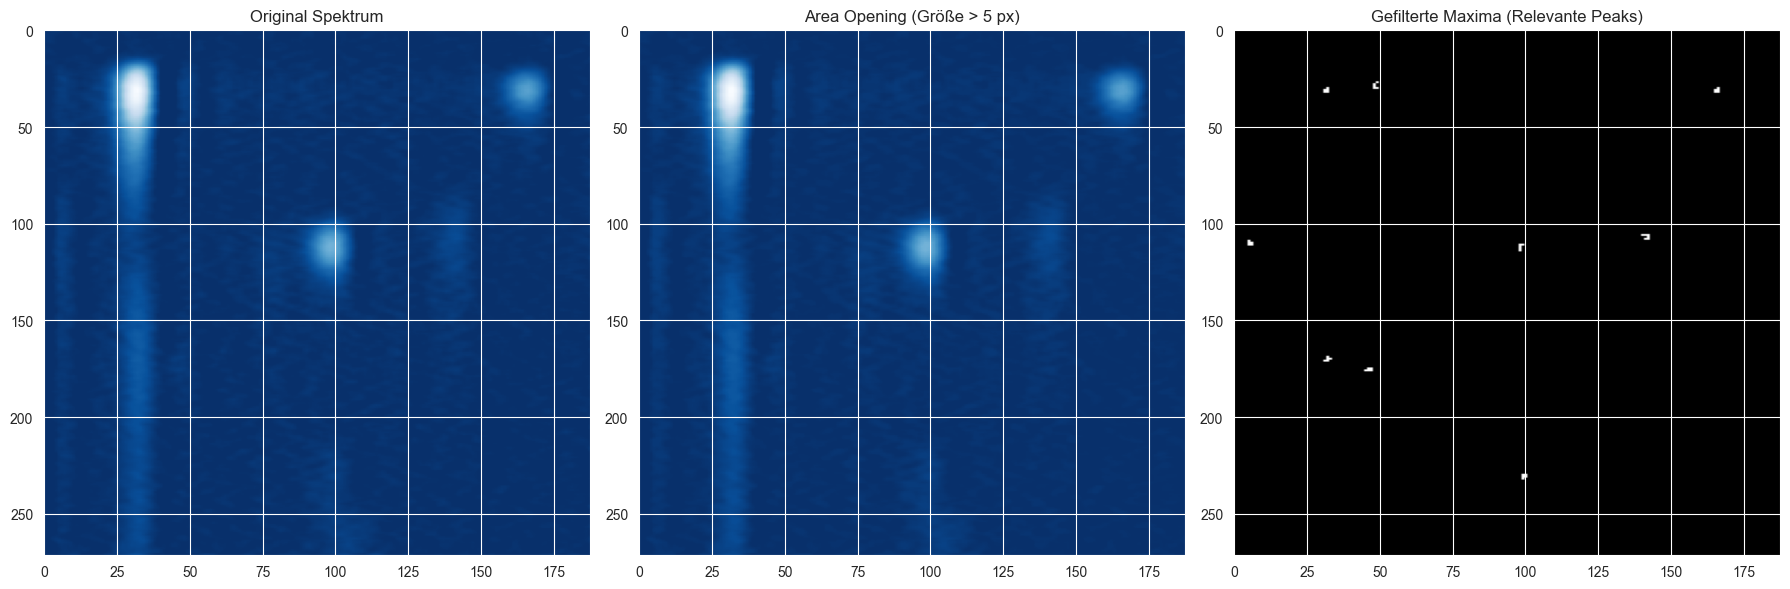

'\nheatmap_dir = Path("./output/Jupyter_Test")\nheatmap_file = heatmap_dir / f"max_tree.png"\n# Create the heatmap plot\nplt.figure(figsize=(10, 10))\n\nsns.heatmap(\n    peak_tree1,\n    annot=False,\n    fmt=".1f",\n    cmap="RdBu_r",\n    cbar=True\n)\n#plt.plot(33, 32, \'y+\', markersize=10)\nplt.title(f"Heatmap")\nplt.xlabel("Drifttime [relative index]")\nplt.ylabel("Retentiontime [relative index]")\nplt.gca().invert_yaxis()\nplt.axis("off")\n# Save the heatmap image.\nplt.savefig(heatmap_file, dpi=300, bbox_inches="tight")\nplt.close()\n'

In [141]:
# Plot a Tree Heatmap
from matplotlib import pyplot as plt
from pathlib import Path
import seaborn as sns
from skimage.morphology import max_tree_local_maxima, max_tree
import numpy as np
from skimage.morphology import area_opening, reconstruction, h_maxima
from skimage.exposure import rescale_intensity

#peak_tree1 = max_tree_local_maxima(spectrum.values, connectivity=2)
parent, traverser = max_tree(spectrum.values, connectivity=2)

# --- METHODE 1: Filtern nach Größe (Area Opening) ---
area_threshold = 5  # Beispiel: Peak muss min. 50 Pixel groß sein
filtered_area = area_opening(spectrum.values, area_threshold=area_threshold, parent=parent, tree_traverser=traverser)

# --- METHODE 2: Filtern nach Höhe/Prominenz (H-Maxima) ---
height_threshold = 20 
filtered_height = reconstruction(spectrum.values - height_threshold, spectrum.values)

# Lokale Maxima im gefilterten Bild finden (für die Punkte-Darstellung)
# h_maxima findet alle lokalen Maxima mit einer Mindesthöhe
peaks_mask = h_maxima(filtered_area, h=height_threshold)

y_coords, x_coords = np.nonzero(peaks_mask)

# Wir kombinieren die Y- und X-Koordinaten-Arrays zu einer Liste von Tupeln:
peak_coordinates = list(zip(y_coords, x_coords))

# --- PLOTTING ---
fig, ax = plt.subplots(1, 3, figsize=(18, 6))

# 1. Original (mit Rauschen)
ax[0].imshow(spectrum.values, cmap='Blues_r', aspect='auto')
ax[0].set_title("Original Spektrum")

# 2. Nach Area-Filterung (Geglättet)
# Hier sollten die kleinen Rausch-Inseln verschwunden sein
ax[1].imshow(filtered_area, cmap='Blues_r', aspect='auto')
ax[1].set_title(f"Area Opening (Größe > {area_threshold} px)")

# 3. Die 'gesäuberten' Maxima (Maske)
# Das ist dein "Sternenhimmel", aber nur mit den wichtigen Sternen
ax[2].imshow(peaks_mask, cmap='gray', aspect='auto')
ax[2].set_title("Gefilterte Maxima (Relevante Peaks)")


plt.tight_layout()
plt.show()


"""
heatmap_dir = Path("./output/Jupyter_Test")
heatmap_file = heatmap_dir / f"max_tree.png"
# Create the heatmap plot
plt.figure(figsize=(10, 10))

sns.heatmap(
    peak_tree1,
    annot=False,
    fmt=".1f",
    cmap="RdBu_r",
    cbar=True
)
#plt.plot(33, 32, 'y+', markersize=10)
plt.title(f"Heatmap")
plt.xlabel("Drifttime [relative index]")
plt.ylabel("Retentiontime [relative index]")
plt.gca().invert_yaxis()
plt.axis("off")
# Save the heatmap image.
plt.savefig(heatmap_file, dpi=300, bbox_inches="tight")
plt.close()
"""

In [137]:
peak_coordinates

[(np.int64(28), np.int64(48)),
 (np.int64(29), np.int64(48)),
 (np.int64(29), np.int64(49)),
 (np.int64(30), np.int64(32)),
 (np.int64(30), np.int64(48)),
 (np.int64(30), np.int64(49)),
 (np.int64(30), np.int64(166)),
 (np.int64(31), np.int64(31)),
 (np.int64(31), np.int64(32)),
 (np.int64(31), np.int64(165)),
 (np.int64(31), np.int64(166)),
 (np.int64(32), np.int64(31)),
 (np.int64(32), np.int64(32)),
 (np.int64(32), np.int64(165)),
 (np.int64(32), np.int64(166)),
 (np.int64(106), np.int64(140)),
 (np.int64(106), np.int64(141)),
 (np.int64(106), np.int64(142)),
 (np.int64(107), np.int64(142)),
 (np.int64(108), np.int64(141)),
 (np.int64(108), np.int64(142)),
 (np.int64(109), np.int64(5)),
 (np.int64(110), np.int64(5)),
 (np.int64(110), np.int64(6)),
 (np.int64(111), np.int64(5)),
 (np.int64(111), np.int64(6)),
 (np.int64(111), np.int64(98)),
 (np.int64(111), np.int64(99)),
 (np.int64(112), np.int64(98)),
 (np.int64(113), np.int64(98)),
 (np.int64(114), np.int64(98)),
 (np.int64(169), 

In [27]:
from matplotlib import pyplot as plt
import numpy as np
plt.figure()
xmax=spectrum.values.max()
(y, x) = np.where(spectrum.values == xmax)
print(y,x)

plot_dir = Path("./output/Jupyter_Test")
plot_file = plot_dir / f"spectrum_1D_.png"
plt.plot(spectrum.values[32,:])
plt.title(f"Spectrum [savgol]")
plt.xlabel("Drifttime [relative index]")
plt.ylabel("Retentiontime [relative index]")
plt.axis("off")
# Save the heatmap image.
plt.savefig(plot_file, bbox_inches="tight")
plt.close()

[31] [32]


In [ ]:
# Import library
from findpeaks import findpeaks
# Initialize with mask method
fp = findpeaks(method='mask', denoise=None, limit=0.2)
# Example 2d image
# Fit mask method on the 2D data
results = fp.fit(spectrum.values)
# The output contains multiple variables
print(results.keys())
# dict_keys(['Xraw', 'Xproc', 'Xdetect'])
fp.plot(figure_order='horizontal')

sns.heatmap(
    results.get("Xranked"),
    annot=False,
    fmt=".1f",
    cmap="RdBu_r",
    cbar=True
)

plot_dir = Path("./output/Jupyter_Test")
plot_file = plot_dir / f"tree_mask_.png"
plt.title(f"Spectrum [savgol]")
plt.xlabel("Drifttime [relative index]")
plt.ylabel("Retentiontime [relative index]")
plt.axis("off")
plt.gca().invert_yaxis()
# Save the heatmap image.
plt.savefig(plot_file, bbox_inches="tight")
plt.close()

[05-12-2025 16:02:18] [findpeaks.stats] [INFO] Scaling image between [0-255] and to uint8
[05-12-2025 16:02:18] [findpeaks.stats] [INFO] Conversion to gray image.
[05-12-2025 16:02:18] [findpeaks.stats] [INFO] Image is already grayscale, no conversion needed.
[05-12-2025 16:02:18] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at 5.
[05-12-2025 16:02:18] [findpeaks.stats] [INFO] Topology
13432it [00:00, 41461.11it/s]
[05-12-2025 16:02:18] [findpeaks.stats] [INFO] Detect peaks using topology method with limit at 5.
[05-12-2025 16:02:18] [findpeaks.stats] [INFO] Topology
51131it [00:01, 47822.12it/s]
[05-12-2025 16:02:20] [findpeaks.findpeaks] [INFO] Fin.
[05-12-2025 16:02:20] [findpeaks.findpeaks] [INFO] Annotating peaks


dict_keys(['Xraw', 'Xproc', 'Xdetect', 'Xranked', 'persistence', 'groups0'])


19it [00:00, 2114.40it/s]
[05-12-2025 16:02:20] [findpeaks.findpeaks] [INFO] Annotating valleys
1it [00:00, 1000.07it/s]


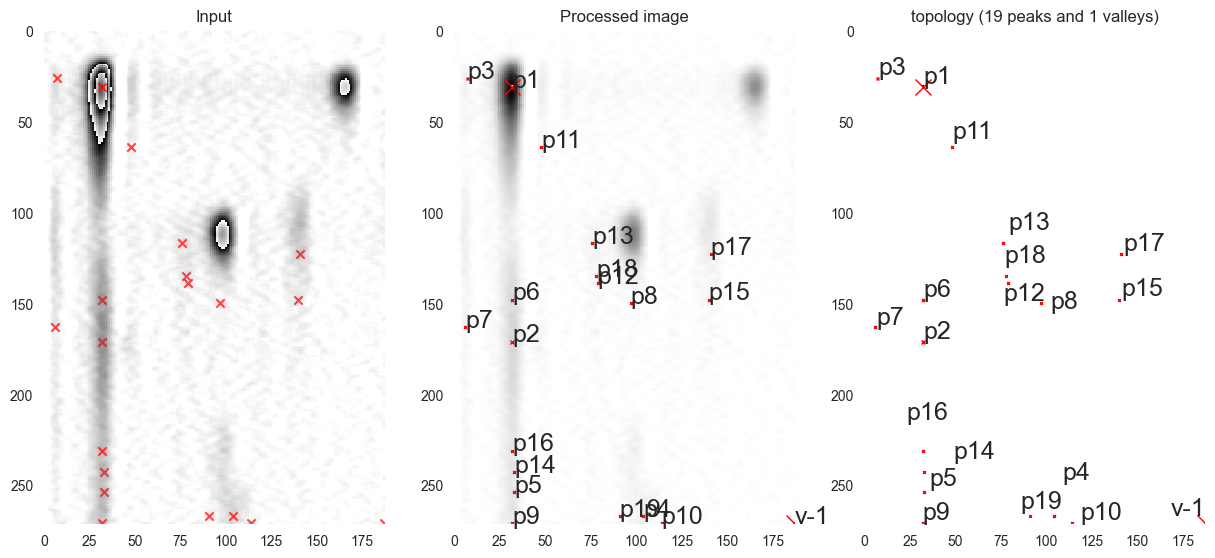

(<Axes: title={'center': 'Input'}>,
 <Axes: title={'center': 'Processed image'}>,
 <Axes: title={'center': 'topology (19 peaks and 1 valleys)'}>)

In [120]:
# Import library
from findpeaks import findpeaks
# Initialize
fp = findpeaks(method='topology', limit=5, denoise=None)
# Fit topology method on the 1d-vector
results = fp.fit(spectrum.values)
# The output contains multiple variables
print(results.keys())
# dict_keys(['Xraw', 'Xproc', 'Xdetect', 'Xranked', 'persistence', 'groups0'])
fp.plot(figure_order='horizontal')

In [73]:
results.get("Xraw")

array([[ 0.        ,  0.        ,  4.87000182, ..., 10.06422732,
         1.07388805,  0.        ],
       [ 8.02298594,  8.52981108, 10.93943621, ...,  2.5309872 ,
         3.68234859,  3.91029753],
       [13.27597496, 13.57163146, 13.14589581, ...,  1.7509991 ,
         5.20658106,  8.93037443],
       ...,
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        ,  2.18321608]], shape=(272, 188))

TypeError: 'findpeaks' object is not subscriptable